# Electric Vehicle Data Analysis

This notebook completes the required tasks:

1. Data Cleaning  
2. Data Preprocessing  
3. Exploratory Data Analysis (EDA)  
4. Hypothesis Testing  
5. Machine Learning Models  

**Target variable:** `range_km`  
Because `range_km` is a continuous numeric variable, this analysis uses **regression models** rather than classification models.


## 1. Import Libraries

In [1]:
# Import all required analysis and modeling libraries.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")


## 2. Load Dataset

In [2]:
# Load and inspect the dataset.
dataset = pd.read_csv("Data_electric_vehicles.csv")
dataset.head()


,brand,top_speed_kmh,battery_capacity_kWh,torque_nm,efficiency_wh_per_km,range_km,acceleration_0_100_s,fast_charging_power_kw_dc,towing_capacity_kg,seats,drivetrain,segment,length_mm,width_mm,height_mm,car_body_type,cargo_volume_l_num
0,Abarth,155,37.8,235.0,156,225,7.0,67.0,0.0,4,FWD,B - Compact,3673,1683,1518,Hatchback,185.0
1,Abarth,155,37.8,235.0,149,225,7.0,67.0,0.0,4,FWD,B - Compact,3673,1683,1518,Hatchback,185.0
2,Abarth,200,50.8,345.0,158,280,5.9,79.0,0.0,5,FWD,JB - Compact,4187,1779,1557,SUV,360.0
3,Abarth,200,50.8,345.0,158,280,6.2,79.0,0.0,5,FWD,JB - Compact,4187,1779,1557,SUV,360.0
4,Aiways,150,60.0,310.0,156,315,7.5,78.0,NaN,5,FWD,JC - Medium,4680,1865,1700,SUV,496.0


In [3]:
# Inspect dataset dimensions and column information.
print("Dataset shape:", dataset.shape)
dataset.info()


Dataset shape: (478, 17)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 478 entries, 0 to 477
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   brand                      478 non-null    object 
 1   top_speed_kmh              478 non-null    int64  
 2   battery_capacity_kWh       478 non-null    float64
 3   torque_nm                  471 non-null    float64
 4   efficiency_wh_per_km       478 non-null    int64  
 5   range_km                   478 non-null    int64  
 6   acceleration_0_100_s       478 non-null    float64
 7   fast_charging_power_kw_dc  477 non-null    float64
 8   towing_capacity_kg         452 non-null    float64
 9   seats                      478 non-null    int64  
 10  drivetrain                 478 non-null    object 
 11  segment                    478 non-null    object 
 12  length_mm                  478 non-null    int64  
 13  width_mm                 

## 3. Data Cleaning

### 3.1 Check missing values

The dataset is checked for missing values before cleaning.


In [4]:
# Summarize missing entries in every column.
missing_summary = pd.DataFrame({
    "Missing Count": dataset.isna().sum(),
    "Missing Percentage": (dataset.isna().mean() * 100).round(2)
})
missing_summary


,Missing Count,Missing Percentage
brand,0,0.00
top_speed_kmh,0,0.00
battery_capacity_kWh,0,0.00
torque_nm,7,1.46
efficiency_wh_per_km,0,0.00
range_km,0,0.00
acceleration_0_100_s,0,0.00
fast_charging_power_kw_dc,1,0.21
towing_capacity_kg,26,5.44
seats,0,0.00


### 3.2 Handle missing values

The missing columns are numerical, so median imputation is used.  
The median is less affected by extreme values than the mean.


In [5]:
# Fill missing numerical values using the column median.
numeric_missing_cols = [
    "torque_nm",
    "fast_charging_power_kw_dc",
    "towing_capacity_kg",
    "cargo_volume_l_num"
]

for col in numeric_missing_cols:
    dataset[col] = dataset[col].fillna(dataset[col].median())

print("Missing values after imputation:")
print(dataset.isna().sum())


Missing values after imputation:
brand                        0
top_speed_kmh                0
battery_capacity_kWh         0
torque_nm                    0
efficiency_wh_per_km         0
range_km                     0
acceleration_0_100_s         0
fast_charging_power_kw_dc    0
towing_capacity_kg           0
seats                        0
drivetrain                   0
segment                      0
length_mm                    0
width_mm                     0
height_mm                    0
car_body_type                0
cargo_volume_l_num           0
dtype: int64


### 3.3 Remove duplicate rows

In [6]:
# Remove duplicate records.
print("Duplicate rows before cleaning:", dataset.duplicated().sum())

dataset = dataset.drop_duplicates().reset_index(drop=True)

print("Dataset shape after removing duplicates:", dataset.shape)
print("Duplicate rows after cleaning:", dataset.duplicated().sum())


Duplicate rows before cleaning: 7
Dataset shape after removing duplicates: (471, 17)
Duplicate rows after cleaning: 0


### 3.4 Check basic descriptive statistics

In [7]:
# Review descriptive statistics for numerical attributes.
dataset.describe().T

,count,mean,std,min,25%,50%,75%,max
top_speed_kmh,471.0,185.452229,34.276990,125.0,160.0,180.0,201.00,325.0
battery_capacity_kWh,471.0,74.121868,20.211561,21.3,60.0,76.5,90.60,118.0
torque_nm,471.0,498.093418,240.580441,113.0,310.0,430.0,679.00,1350.0
efficiency_wh_per_km,471.0,163.012739,34.430501,109.0,142.5,155.0,178.00,370.0
range_km,471.0,393.694268,102.844356,135.0,320.0,400.0,470.00,685.0
acceleration_0_100_s,471.0,6.886837,2.744154,2.2,4.8,6.6,8.25,19.1
fast_charging_power_kw_dc,471.0,124.760085,57.676572,29.0,80.0,113.0,150.00,281.0
towing_capacity_kg,471.0,1050.046709,714.512321,0.0,500.0,1000.0,1600.00,2500.0
seats,471.0,5.269639,1.009272,2.0,5.0,5.0,5.00,9.0
length_mm,471.0,4681.008493,367.102861,3620.0,4440.0,4720.0,4961.00,5908.0


## 4. Exploratory Data Analysis (EDA)

### Visualization 1: Distribution of EV Range

This histogram shows how the driving range values are distributed across the dataset.


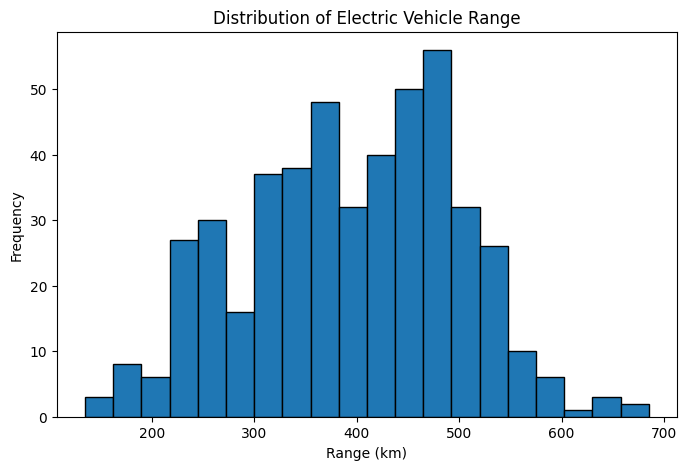

Mean range: 393.69 km
Median range: 400.0 km


In [8]:
# Visualize the frequency distribution of EV ranges.
plt.figure(figsize=(8, 5))
plt.hist(dataset["range_km"], bins=20, edgecolor="black")
plt.title("Distribution of Electric Vehicle Range")
plt.xlabel("Range (km)")
plt.ylabel("Frequency")
plt.show()

print("Mean range:", round(dataset["range_km"].mean(), 2), "km")
print("Median range:", round(dataset["range_km"].median(), 2), "km")


**Interpretation:** The plot shows the spread of EV driving ranges. Most vehicles are concentrated around the middle range values, while fewer vehicles appear at the very low and very high ends.


### Visualization 2: Battery Capacity vs Range

A scatter plot is used to inspect the relationship between battery capacity and driving range.


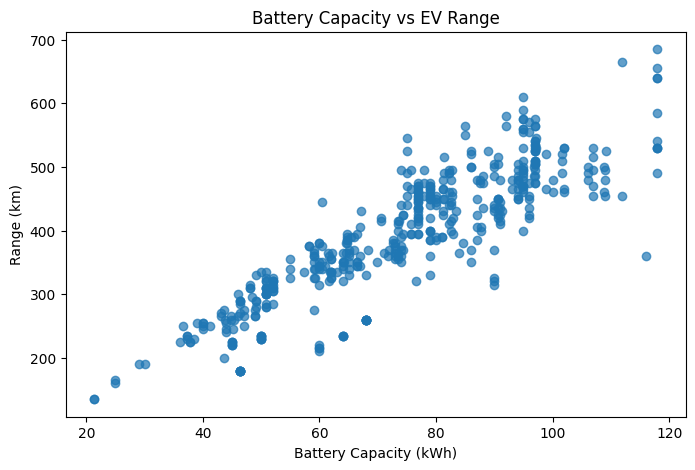

Correlation: 0.878


In [9]:
# Explore the relationship between battery capacity and range.
plt.figure(figsize=(8, 5))
plt.scatter(dataset["battery_capacity_kWh"], dataset["range_km"], alpha=0.7)
plt.title("Battery Capacity vs EV Range")
plt.xlabel("Battery Capacity (kWh)")
plt.ylabel("Range (km)")
plt.show()

corr_value = dataset["battery_capacity_kWh"].corr(dataset["range_km"])
print("Correlation:", round(corr_value, 3))


**Interpretation:** Battery capacity has a strong positive relationship with range. Vehicles with larger batteries generally travel farther.


### Visualization 3: Range by Car Body Type

A box plot compares the distribution of range for different vehicle body types.


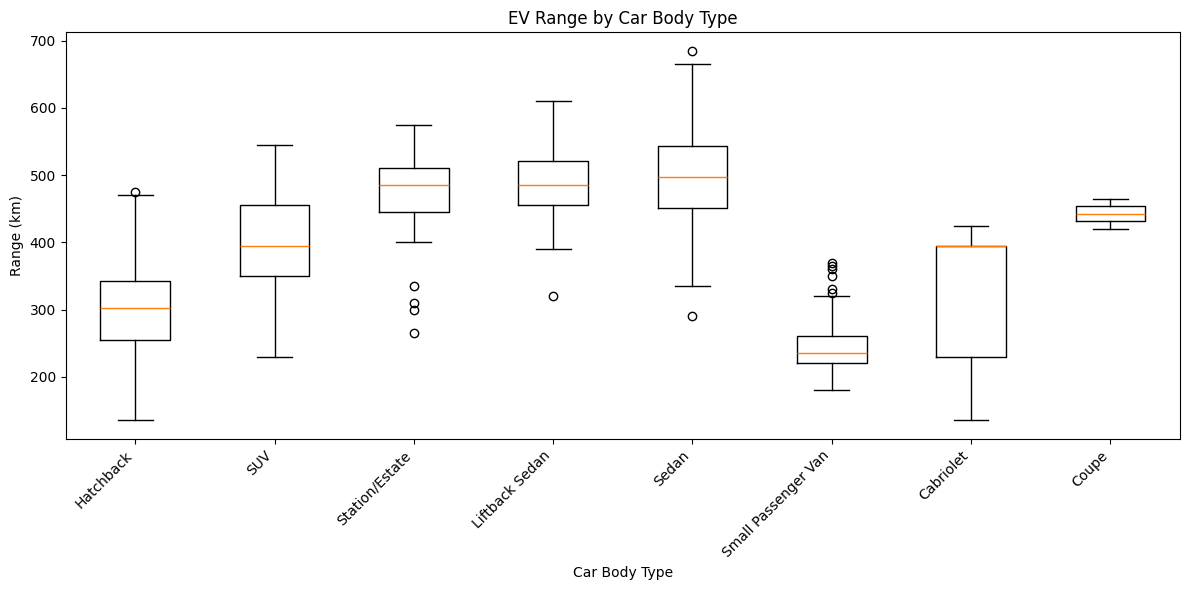

car_body_type
Sedan                  497.5
Liftback Sedan         485.0
Station/Estate         485.0
Coupe                  442.5
SUV                    395.0
Cabriolet              395.0
Hatchback              302.5
Small Passenger Van    235.0
Name: range_km, dtype: float64


In [10]:
# Compare EV range distributions across vehicle body types.
body_types = dataset["car_body_type"].unique()
range_groups = [
    dataset.loc[dataset["car_body_type"] == body_type, "range_km"]
    for body_type in body_types
]

plt.figure(figsize=(12, 6))
plt.boxplot(range_groups, labels=body_types, showfliers=True)
plt.title("EV Range by Car Body Type")
plt.xlabel("Car Body Type")
plt.ylabel("Range (km)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print(dataset.groupby("car_body_type")["range_km"].median().sort_values(ascending=False))


**Interpretation:** Median driving range differs across body types. Sedan and liftback-sedan vehicles have relatively high median ranges, while small passenger vans and hatchbacks have lower median ranges in this dataset.


### Visualization 4: Correlation Heatmap

The heatmap shows correlations among numerical variables. Values close to +1 indicate strong positive relationships, while values close to -1 indicate strong negative relationships.


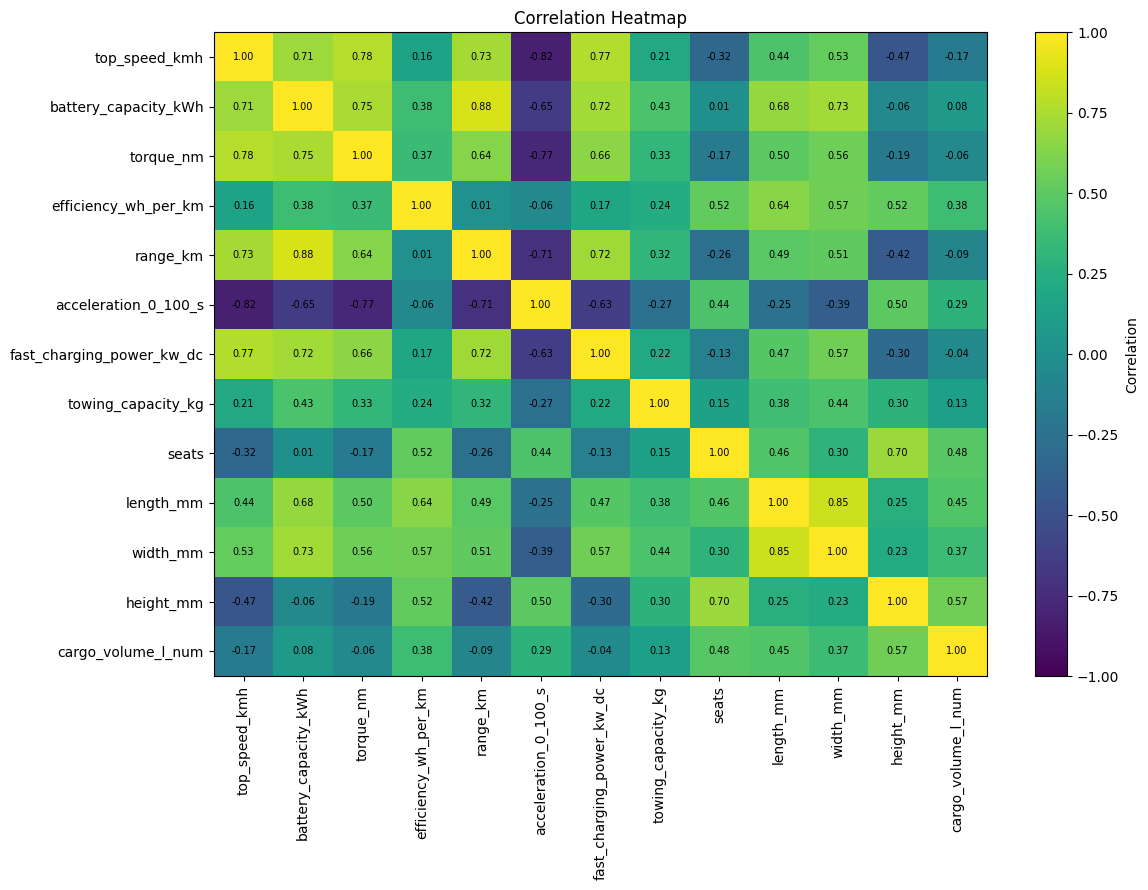

In [11]:
# Visualize correlations among numeric attributes.
numeric_data = dataset.select_dtypes(include=np.number)
corr_matrix = numeric_data.corr()

fig, ax = plt.subplots(figsize=(12, 9))
im = ax.imshow(corr_matrix, aspect="auto", vmin=-1, vmax=1)

ax.set_xticks(np.arange(len(corr_matrix.columns)))
ax.set_yticks(np.arange(len(corr_matrix.columns)))
ax.set_xticklabels(corr_matrix.columns, rotation=90)
ax.set_yticklabels(corr_matrix.columns)

for i in range(len(corr_matrix.columns)):
    for j in range(len(corr_matrix.columns)):
        ax.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}",
                ha="center", va="center", fontsize=7)

fig.colorbar(im, ax=ax, label="Correlation")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


**Interpretation:** `battery_capacity_kWh` has one of the strongest positive correlations with `range_km`. `top_speed_kmh` is also positively related to range, while `acceleration_0_100_s` shows a negative relationship with range.


## 5. Hypothesis Testing

### Hypothesis Test 1: Pearson Correlation Test

**Question:** Is battery capacity significantly related to EV range?

- **H₀:** There is no linear relationship between battery capacity and EV range (`r = 0`).
- **H₁:** There is a significant linear relationship between battery capacity and EV range (`r ≠ 0`).
- **Significance level:** α = 0.05


In [12]:
# Run the Pearson correlation hypothesis test.
r_value, p_value_1 = stats.pearsonr(
    dataset["battery_capacity_kWh"],
    dataset["range_km"]
)

print("Pearson correlation coefficient:", round(r_value, 4))
print("p-value:", p_value_1)

if p_value_1 < 0.05:
    print("Conclusion: Reject H0.")
    print("There is a statistically significant relationship between battery capacity and EV range.")
else:
    print("Conclusion: Fail to reject H0.")
    print("There is not enough evidence of a significant relationship.")


Pearson correlation coefficient: 0.8777
p-value: 6.4471224447505585e-152
Conclusion: Reject H0.
There is a statistically significant relationship between battery capacity and EV range.


### Hypothesis Test 2: Welch's Independent Samples t-test

**Question:** Is the mean EV range different between SUVs and Sedans?

- **H₀:** Mean SUV range = Mean Sedan range.
- **H₁:** Mean SUV range ≠ Mean Sedan range.
- **Significance level:** α = 0.05

Welch's t-test is used because it does not require the two groups to have equal variances.


In [13]:
# Compare mean SUV and sedan ranges using Welch's t-test.
suv_range = dataset.loc[dataset["car_body_type"] == "SUV", "range_km"]
sedan_range = dataset.loc[dataset["car_body_type"] == "Sedan", "range_km"]

t_stat, p_value_2 = stats.ttest_ind(
    suv_range,
    sedan_range,
    equal_var=False
)

print("SUV mean range:", round(suv_range.mean(), 2), "km")
print("Sedan mean range:", round(sedan_range.mean(), 2), "km")
print("t-statistic:", round(t_stat, 4))
print("p-value:", p_value_2)

if p_value_2 < 0.05:
    print("Conclusion: Reject H0.")
    print("The mean EV range is significantly different between SUVs and Sedans.")
else:
    print("Conclusion: Fail to reject H0.")
    print("There is not enough evidence of a difference in mean range.")


SUV mean range: 396.85 km
Sedan mean range: 499.19 km
t-statistic: -9.1744
p-value: 2.1201392223635518e-14
Conclusion: Reject H0.
The mean EV range is significantly different between SUVs and Sedans.


## 6. Data Preprocessing

### 6.1 Define features and target

`range_km` is the target variable. The other columns are used as input features.


In [14]:
# Define prediction inputs and target.
X = dataset.drop(columns=["range_km"])
y = dataset["range_km"]

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (471, 16)
y shape: (471,)


### 6.2 Identify categorical and numerical columns

Preprocessing techniques used:

- **Categorical encoding:** One-Hot Encoding
- **Feature scaling:** StandardScaler for numerical columns
- **Feature selection:** SelectKBest with `f_regression`
- **Train-test split:** 80% training and 20% testing


In [15]:
# Classify predictors as categorical or numerical.
categorical_features = X.select_dtypes(include="object").columns.tolist()
numerical_features = X.select_dtypes(exclude="object").columns.tolist()

print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)


Categorical features: ['brand', 'drivetrain', 'segment', 'car_body_type']
Numerical features: ['top_speed_kmh', 'battery_capacity_kWh', 'torque_nm', 'efficiency_wh_per_km', 'acceleration_0_100_s', 'fast_charging_power_kw_dc', 'towing_capacity_kg', 'seats', 'length_mm', 'width_mm', 'height_mm', 'cargo_volume_l_num']


### 6.3 Train-test split

In [16]:
# Split data into training and testing subsets.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)


Training set: (376, 16)
Testing set: (95, 16)


### 6.4 Create preprocessing pipeline

In [17]:
# Configure transformations and feature selection.
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

feature_selector = SelectKBest(score_func=f_regression, k=15)


## 7. Machine Learning Models

Two regression models are developed:

1. **Linear Regression**
2. **Random Forest Regressor**

They are evaluated using:

- **MAE** – Mean Absolute Error
- **RMSE** – Root Mean Squared Error
- **R² Score** – proportion of variance explained by the model


### Model 1: Linear Regression

In [18]:
# Train and test a Linear Regression model.
linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("feature_selection", feature_selector),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)

print("Linear Regression trained successfully.")


Linear Regression trained successfully.


### Model 2: Random Forest Regressor

In [19]:
# Train and test a Random Forest Regression model.
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("feature_selection", feature_selector),
    ("model", RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ))
])

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

print("Random Forest Regressor trained successfully.")


Random Forest Regressor trained successfully.


## 8. Model Evaluation

In [20]:
# Evaluate both regression models with the same metrics.
def regression_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return mae, rmse, r2

linear_mae, linear_rmse, linear_r2 = regression_metrics(y_test, linear_pred)
rf_mae, rf_rmse, rf_r2 = regression_metrics(y_test, rf_pred)

results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest Regressor"],
    "MAE": [linear_mae, rf_mae],
    "RMSE": [linear_rmse, rf_rmse],
    "R2 Score": [linear_r2, rf_r2]
})

results.round(4)


,Model,MAE,RMSE,R2 Score
0,Linear Regression,19.5365,24.3803,0.9356
1,Random Forest Regressor,13.9415,18.6543,0.9623


In [21]:
# Identify the model with the highest test R-squared.
best_model = results.loc[results["R2 Score"].idxmax(), "Model"]
print("Best model based on R2 Score:", best_model)


Best model based on R2 Score: Random Forest Regressor


### Actual vs Predicted Range

This plot helps visually compare the Random Forest predictions with the actual test values.


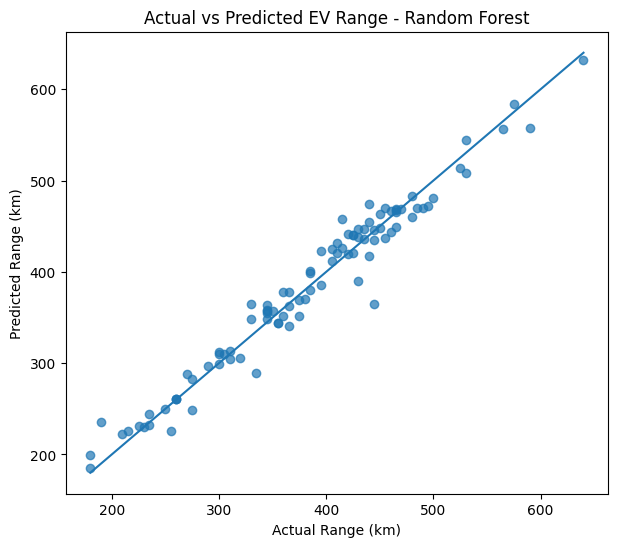

In [22]:
# Compare predicted values to observed EV ranges.
plt.figure(figsize=(7, 6))
plt.scatter(y_test, rf_pred, alpha=0.7)

min_value = min(y_test.min(), rf_pred.min())
max_value = max(y_test.max(), rf_pred.max())
plt.plot([min_value, max_value], [min_value, max_value])

plt.title("Actual vs Predicted EV Range - Random Forest")
plt.xlabel("Actual Range (km)")
plt.ylabel("Predicted Range (km)")
plt.show()


## 9. Final Conclusion

- Missing numerical values were handled using median imputation.
- Duplicate rows were removed.
- Categorical features were encoded using One-Hot Encoding.
- Numerical variables were standardized.
- Feature selection was performed using `SelectKBest`.
- Four EDA visualizations were created and interpreted.
- Two hypothesis tests were completed with H₀, H₁, p-values, and conclusions.
- Linear Regression and Random Forest Regressor were trained and evaluated.
- The model with the higher R² and lower error values can be selected as the better model for predicting EV range.
